# Preproccessing of the dataset

In [107]:
import pandas as pd
import json
import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageOps
import numpy as np
from tqdm import tqdm
from keras.utils import to_categorical

IMG_SIZE    = 224
NUM_CLASSES = 11

CACHE = f'../raw_data/crops_{IMG_SIZE}.npz'


# ---------------------------------------
# Loading the image data
# ---------------------------------------

In [108]:
train_data_path = '../raw_data/train/train_data/'
train_labels_path = '../raw_data/train/train_labels.json'
test_data_path = '../raw_data/test/test_data/'
test_labels_path = '../raw_data/test/test_labels.json'


In [114]:
def load_split(labels_path, data_path):
    with open(labels_path) as f:
        data = json.load(f)

    images = pd.DataFrame(data['images']).rename(columns={'id': 'image_id'})
    annotations = pd.DataFrame(data['annotations']).rename(columns={'id': 'egg_id'})
    categories = pd.DataFrame(data['categories']).rename(columns={'id': 'category_id', 'name': 'category_name'})

    df = (images
          .merge(annotations, on='image_id')
          .merge(categories, on='category_id')
          .drop(columns=['license', 'coco_url', 'supercategory']))
    df['path'] = df['file_name'].apply(lambda n: os.path.join(data_path, n))
    return df

In [115]:
train_df = load_split(train_labels_path, train_data_path)
test_df  = load_split(test_labels_path,  test_data_path)

# ---------------------------------------
# Visualisation
# ---------------------------------------

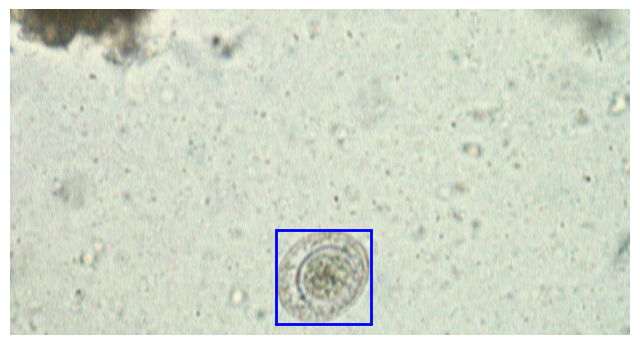

In [110]:
def show_with_box(row: pd.Series):
    img = Image.open(row['path'])
    x, y, w, h = row['bbox']

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(img)
    ax.add_patch(patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='blue', facecolor='none'))
    ax.axis('off')
    plt.show()

show_with_box(train_df.iloc[10])

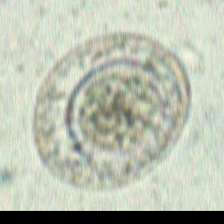

In [111]:
def crop_egg(row: pd.Series, margin: float = 0.2, img_size: int = 224):
    img = ImageOps.exif_transpose(Image.open(row['path'])).convert('RGB')
    x, y, w, h = row['bbox']

    # centre of the egg
    cx, cy = x + w / 2, y + h / 2

    # one side length for both directions: longest egg side + 20% margin on each side
    side = max(w, h) * (1 + 2 * margin)

    left   = cx - side / 2
    top    = cy - side / 2
    right  = cx + side / 2
    bottom = cy + side / 2

    crop = img.crop((left, top, right, bottom))
    return crop.resize((img_size, img_size))

crop_egg(train_df.iloc[10])

### This code is how we get all image_ids that contain 2 or more eggs in one image.

  **`multiple_eggs = train_df.value_counts('image_id').sort_values(ascending=False).head(30)`**

# ---------------------------------------
# One-Hot Encoding, Arrays
# ---------------------------------------

In [ ]:
def build_arrays(df: pd.DataFrame, img_size: int = IMG_SIZE):
    df = df.reset_index(drop=True)                       # row i in df == X[i]
    X = np.zeros((len(df), img_size, img_size, 3), dtype=np.uint8)

    for i, row in tqdm(df.iterrows(), total=len(df), desc='Building arrays'):
        X[i] = np.asarray(crop_egg(row, img_size=img_size))

    y = to_categorical(x=df['category_id'], num_classes=NUM_CLASSES) # one-hot, shape (n, 11)
    return X, y

In [113]:
def get_cropped_arrays(cache_path: str = CACHE):
    if os.path.exists(CACHE):
        data = np.load(CACHE)
        X_train, y_train = data['X_train'], data['y_train']
        X_test,  y_test  = data['X_test'],  data['y_test']
    else:
        X_train, y_train = build_arrays(train_df)
        X_test,  y_test  = build_arrays(test_df)
        np.savez(CACHE, X_train=X_train, y_train=y_train,
                        X_test=X_test,   y_test=y_test)

    return X_train, y_train, X_test, y_test

In [118]:
X_train, y_train, X_test, y_test = get_cropped_arrays()
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((11031, 224, 224, 3), (11031, 11), (2228, 224, 224, 3), (2228, 11))